# PROJETO DE COLETA DE DADOS
## Coleta e Análise de Dados Meteorológicos de Cidades do Nordeste Brasileiro Utilizando Python e Google Colab

**Autor:** Carlos Souza do Nascimento  

**Data:** 07/11/2026

**Disciplina:** Introdução à Ciência de Dados  

**Fonte de dados:** Open-Meteo — Historical Weather API

**Ambiente:** Google Colab / Python 3
---

## 1. OBJETIVO
[Descreva o objetivo do projeto em 2-3 frases]
Coletar dados meteorológicos de dez cidades do Nordeste brasileiro por meio de uma API pública, organizar um dataset com pelo menos dez registros, realizar limpeza e análise exploratória e documentar os resultados. Em seguida, serão analisadas temperatura, precipitação e evapotranspiração de referência (ET₀), variáveis relevantes para compreender condições ambientais às quais as plantas estão expostas.

**Pergunta orientadora:** como as condições meteorológicas observadas em outubro de 2026 diferiram entre dez cidades nordestinas?

**Justificativa:** o tema Clima consta da lista sugerida na aula e permite relacionar a Ciência de Dados à Biologia Vegetal, minha área de interesse.


## 2. FONTES DE DADOS
| Fonte | URL | Método | Dados Coletados |
|-------|-----|--------|-----------------|
| Open-Meteo — Historical Weather API | Historical Weather API	https://archive-api.open-meteo.com/v1/archive | AAPI (HTTP GET, JSON) | Temperaturas diárias, precipitação e ET₀ |
| Documentação técnica| https://open-meteo.com/en/docs/historical-weather-api  |Consulta  | Definição das variáveis, unidades e limitações |

## 3. METODOLOGIA
### 3.1 Coleta
-Definir cidades, coordenadas, período e variáveis.
-Fazer uma requisição HTTP GET para a Open-Meteo.
-Verificar o status HTTP e a estrutura JSON.
-Converter o JSON em um DataFrame com uma linha por cidade e dia.
-Preservar o dataset bruto quando a API estiver acessível.

### 3.2 Limpeza
-Verificar valores ausentes (isna()), converter datas (to_datetime()) e valores numéricos (to_numeric()).
-Remover duplicatas por cidade + data; descartar apenas linhas sem dados essenciais, informando o quantitativo.
-Não preencher automaticamente precipitação ausente com zero: ausência de medição não significa ausência de chuva.

### 3.3 Processamento
[Descreva transformações feitas]
-Calcular, por cidade, temperatura média dos 31 dias; temperatura máxima do mês; temperatura mínima do mês; soma da precipitação e da ET₀.
-Verificar pelo menos dez registros válidos; gerar CSV, estatísticas, gráficos e documentação.


**Passo A — Importação das bibliotecas**
requests comunica-se com a API; pandas organiza e limpa tabelas; matplotlib cria gráficos; datetime e pathlib registram data e arquivos. JSON é o formato de resposta da API.

In [1]:
import io
import json
import zipfile
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("Ambiente configurado com sucesso!")
print("Pandas:", pd.__version__)
print("Requests:", requests.__version__)


Ambiente configurado com sucesso!
Pandas: 2.2.3
Requests: 2.32.4


**Passo B — Planejamento da coleta**
cidades guarda nome, latitude e longitude. O params será transmitido como parâmetros da requisição e indica ao servidor quais dados retornar. Usamos dez cidades e o período fechado de outubro de 2026.

In [2]:
cidades = [
    {"cidade": "Aracaju", "latitude": -10.9162, "longitude": -37.0731},
    {"cidade": "Maceió", "latitude": -9.6499, "longitude": -35.7089},
    {"cidade": "Recife", "latitude": -8.0476, "longitude": -34.8770},
    {"cidade": "João Pessoa", "latitude": -7.1153, "longitude": -34.8610},
    {"cidade": "Natal", "latitude": -5.7945, "longitude": -35.2110},
    {"cidade": "Fortaleza", "latitude": -3.7319, "longitude": -38.5267},
    {"cidade": "Teresina", "latitude": -5.0919, "longitude": -42.8034},
    {"cidade": "São Luís", "latitude": -2.5307, "longitude": -44.3068},
    {"cidade": "Salvador", "latitude": -12.9777, "longitude": -38.5016},
    {"cidade": "Petrolina", "latitude": -9.3891, "longitude": -40.5031},
]

url_api = "https://archive-api.open-meteo.com/v1/archive"
variaveis = [
    "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
    "precipitation_sum", "et0_fao_evapotranspiration"
]
params = {
    "latitude": ",".join(str(c["latitude"]) for c in cidades),
    "longitude": ",".join(str(c["longitude"]) for c in cidades),
    "start_date": "2026-10-01", "end_date": "2026-10-31",
    "daily": ",".join(variaveis),
    "timezone": "America/Maceio",
    "models": "era5",
}
url_consulta = requests.Request("GET", url_api, params=params).prepare().url
print("Total de cidades:", len(cidades))
print("Período:", params["start_date"], "a", params["end_date"])
print("Endereço de consulta:", url_consulta)


Total de cidades: 10
Período: 2026-10-01 a 2026-10-31
Endereço de consulta: https://archive-api.open-meteo.com/v1/archive?latitude=-10.9162%2C-9.6499%2C-8.0476%2C-7.1153%2C-5.7945%2C-3.7319%2C-5.0919%2C-2.5307%2C-12.9777%2C-9.3891&longitude=-37.0731%2C-35.7089%2C-34.877%2C-34.861%2C-35.211%2C-38.5267%2C-42.8034%2C-44.3068%2C-38.5016%2C-40.5031&start_date=2026-10-01&end_date=2026-10-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum%2Cet0_fao_evapotranspiration&timezone=America%2FMaceio&models=era5


**Passo C — Coleta pela API e contingência offline**
O modo padrão é api. requests.get() faz a chamada; raise_for_status() identifica erros HTTP; .json() converte a resposta em objetos Python. Uma falha de rede é identificada claramente e aciona o snapshot real já verificado, sem criar dados fictícios.

Para testar diretamente os dados de referência, altere modo_coleta para "snapshot". Isso não substitui a coleta exigida pelo professor; para comprovar a etapa de API, use "api" com internet.

In [9]:
# Snapshot da Open-Meteo (08/11/2026): 10 cidades, 31 dias, dados mensais agregados.
SNAPSHOT_CSV = """cidade,latitude_consulta,longitude_consulta,dias_validos,temp_media_c,temp_max_c,temp_min_c,precip_total_mm,et0_total_mm
Aracaju,-10.9162,-37.0731,31,26.84,32.3,23.3,11.9,173.05
Maceió,-9.6499,-35.7089,31,26.5,32.7,22.2,30.1,158.95
Recife,-8.0476,-34.877,31,27.24,33.5,21.9,25.1,162.97
João Pessoa,-7.1153,-34.861,31,26.8,31.2,22.6,22.1,163.07
Natal,-5.7945,-35.211,31,26.58,28.7,24.3,32.6,165.2
Fortaleza,-3.7319,-38.5267,31,27.45,31,24.8,8.3,177.82
Teresina,-5.0919,-42.8034,31,30.96,40.1,21.3,0.9,209.93
São Luís,-2.5307,-44.3068,31,27.98,32.3,25.6,4.6,171.79
Salvador,-12.9777,-38.5016,31,26.48,32,23.6,38.2,164.45
Petrolina,-9.3891,-40.5031,31,30.12,38.9,21.6,7.2,246.45
"""
modo_coleta = "api"  # Use "snapshot" para trabalhar sem conexão.
respostas_api = None
origem_execucao = None
problema_coleta = None
if modo_coleta == "api":
    try:
        resposta = requests.get(url_api, params=params, timeout=15)
        resposta.raise_for_status()
        respostas_api = resposta.json()
        if not isinstance(respostas_api, list) or len(respostas_api) != len(cidades):
            raise ValueError("Quantidade de respostas diferente das 10 cidades.")
        for item in respostas_api:
            if "daily" not in item or not all(v in item["daily"] for v in ["time", *variaveis]):
                raise ValueError("Uma cidade não contém as variáveis esperadas.")
        # Verifica se todas as cidades possuem as datas e os 31 valores por variável.
        datas_esperadas = pd.date_range(params["start_date"], params["end_date"], freq="D").strftime("%Y-%m-%d").tolist()
        total_dias = len(datas_esperadas)
        for indice, item in enumerate(respostas_api):
            diario = item["daily"]
            if diario["time"] != datas_esperadas:
                raise ValueError(f"Datas incorretas ou ausentes em {cidades[indice]['cidade']}.")
            if any(len(diario[v]) != total_dias for v in variaveis):
                raise ValueError(f"Uma variável de {cidades[indice]['cidade']} não possui {total_dias} valores.")
        origem_execucao = "API Open-Meteo (coleta ativa)"
        print(f"✅ Validação aprovada: {len(cidades)} cidades × {total_dias} dias = {len(cidades) * total_dias} observações diárias.")
        print("✅ Coleta feita diretamente pela API.")
    except (requests.RequestException, ValueError, KeyError, TypeError) as erro:
        problema_coleta = f"{type(erro).__name__}: {erro}"
        respostas_api = None
        origem_execucao = "Snapshot verificado em 08/11/2026 — sem nova coleta"
        print("⚠️ Falha na API ou na validação. Usando snapshot de referência.")
        print("Motivo:", problema_coleta)
else:
    origem_execucao = "Snapshot verificado em 08/11/2026 — sem nova coleta"
    print("⚠️ Modo snapshot selecionado: consulta à API não realizada.")


✅ Validação aprovada: 10 cidades × 31 dias = 310 observações diárias.
✅ Coleta feita diretamente pela API.


**Passo D — Transformar os dados em DataFrame**
Quando a API responde, o loop percorre cada cidade e cada dia. DataFrame representa uma tabela de linhas e colunas. Se o notebook estiver sem internet, lê-se apenas o CSV agregado de referência, explicitando que não há respostas diárias novas.

In [5]:
if respostas_api is not None:
    registros_diarios = []
    for cidade, retorno in zip(cidades, respostas_api):
        diario = retorno["daily"]
        n_dias = len(diario["time"])
        if any(len(diario[variavel]) != n_dias for variavel in variaveis):
            raise ValueError("Comprimento inconsistente nas listas de dados diários.")
        for i, dia in enumerate(diario["time"]):
            registro = {
                "cidade": cidade["cidade"],
                "latitude_consulta": cidade["latitude"],
                "longitude_consulta": cidade["longitude"],
                "data": dia,
            }
            registro.update({v: diario[v][i] for v in variaveis})
            registros_diarios.append(registro)

    df_bruto = pd.DataFrame(registros_diarios)
    df_bruto.to_csv("clima_dados_diarios_brutos.csv", index=False, encoding="utf-8-sig")
    print(f"Registros diários originais: {len(df_bruto)} (previstos: 310)")
    display(df_bruto.head())
else:
    df_bruto = None
    df_snapshot = pd.read_csv(io.StringIO(SNAPSHOT_CSV))
    print("Registros agregados do snapshot:", len(df_snapshot))
    display(df_snapshot.head())


Registros diários originais: 310 (previstos: 310)


,cidade,latitude_consulta,longitude_consulta,data,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,et0_fao_evapotranspiration
0,Aracaju,-10.9162,-37.0731,2026-10-01,27.1,30.3,24.5,0.1,5.17
1,Aracaju,-10.9162,-37.0731,2026-10-02,27.1,31.0,24.4,0.3,6.12
2,Aracaju,-10.9162,-37.0731,2026-10-03,26.9,29.9,25.0,0.6,5.46
3,Aracaju,-10.9162,-37.0731,2026-10-04,26.5,29.4,24.5,0.8,5.71
4,Aracaju,-10.9162,-37.0731,2026-10-05,26.0,28.3,23.8,1.7,4.76


**Passo E — Limpeza e unificação**
As funções to_datetime() e to_numeric() convertem formatos. drop_duplicates() elimina duplicidades. dropna() só retira observações diárias com variáveis essenciais ausentes. Para variáveis de chuva, NaN não deve ser convertido automaticamente em zero. O resultado contém uma linha por cidade e consolida os 31 dias.

In [6]:
colunas_finais = [
    "cidade", "latitude_consulta", "longitude_consulta", "dias_validos",
    "temp_media_c", "temp_max_c", "temp_min_c",
    "precip_total_mm", "et0_total_mm"
]

if df_bruto is not None:
    print("Nulos antes da limpeza (dados diários):")
    print(df_bruto.isna().sum())
    df_limpo = df_bruto.copy()
    df_limpo["data"] = pd.to_datetime(df_limpo["data"], errors="coerce")
    for coluna in variaveis:
        df_limpo[coluna] = pd.to_numeric(df_limpo[coluna], errors="coerce")
    antes = len(df_limpo)
    df_limpo = df_limpo.drop_duplicates(subset=["cidade", "data"])
    apos_duplicatas = len(df_limpo)
    df_limpo = df_limpo.dropna(subset=["data", *variaveis])
    print("Duplicatas removidas:", antes - apos_duplicatas)
    print("Linhas com dados essenciais ausentes removidas:", apos_duplicatas - len(df_limpo))
    print("Linhas diárias válidas:", len(df_limpo))

    df_final = df_limpo.groupby("cidade", as_index=False, sort=False).agg(
        latitude_consulta=("latitude_consulta", "first"),
        longitude_consulta=("longitude_consulta", "first"),
        dias_validos=("data", "nunique"),
        temp_media_c=("temperature_2m_mean", "mean"),
        temp_max_c=("temperature_2m_max", "max"),
        temp_min_c=("temperature_2m_min", "min"),
        precip_total_mm=("precipitation_sum", "sum"),
        et0_total_mm=("et0_fao_evapotranspiration", "sum"),
    )[colunas_finais]
    df_final[["temp_media_c", "temp_max_c", "temp_min_c", "precip_total_mm", "et0_total_mm"]] = (
        df_final[["temp_media_c", "temp_max_c", "temp_min_c", "precip_total_mm", "et0_total_mm"]].round(2)
    )
else:
    df_final = df_snapshot.copy()
    for coluna in ["latitude_consulta", "longitude_consulta", *colunas_finais[4:]]:
        df_final[coluna] = pd.to_numeric(df_final[coluna], errors="coerce")
    df_final["dias_validos"] = pd.to_numeric(df_final["dias_validos"], errors="coerce").astype("Int64")
    df_final = df_final.drop_duplicates(subset=["cidade"]).dropna(subset=colunas_finais)
    df_final = df_final[colunas_finais]

print("Origem da execução:", origem_execucao)
print("Dimensões do dataset final (linhas, colunas):", df_final.shape)
display(df_final)


Nulos antes da limpeza (dados diários):
cidade                        0
latitude_consulta             0
longitude_consulta            0
data                          0
temperature_2m_mean           0
temperature_2m_max            0
temperature_2m_min            0
precipitation_sum             0
et0_fao_evapotranspiration    0
dtype: int64
Duplicatas removidas: 0
Linhas com dados essenciais ausentes removidas: 0
Linhas diárias válidas: 310
Origem da execução: API Open-Meteo (coleta ativa)
Dimensões do dataset final (linhas, colunas): (10, 9)


,cidade,latitude_consulta,longitude_consulta,dias_validos,temp_media_c,temp_max_c,temp_min_c,precip_total_mm,et0_total_mm
0,Aracaju,-10.9162,-37.0731,31,26.84,32.3,23.3,11.9,173.05
1,Maceió,-9.6499,-35.7089,31,26.50,32.7,22.2,30.1,158.95
2,Recife,-8.0476,-34.8770,31,27.24,33.5,21.9,25.1,162.97
3,João Pessoa,-7.1153,-34.8610,31,26.80,31.2,22.6,22.1,163.07
4,Natal,-5.7945,-35.2110,31,26.58,28.7,24.3,32.6,165.20
5,Fortaleza,-3.7319,-38.5267,31,27.45,31.0,24.8,8.3,177.82
6,Teresina,-5.0919,-42.8034,31,30.96,40.1,21.3,0.9,209.93
7,São Luís,-2.5307,-44.3068,31,27.98,32.3,25.6,4.6,171.79
8,Salvador,-12.9777,-38.5016,31,26.48,32.0,23.6,38.2,164.45
9,Petrolina,-9.3891,-40.5031,31,30.12,38.9,21.6,7.2,246.45


**Passo F — Auditoria e testes de consistência**
assert encerra a execução se uma verificação for falsa. São conferidos o mínimo de dez registros, as dez cidades distintas, valores não negativos para precipitação e ET₀, coerência entre mínima, média e máxima e ausência de nulos.

In [8]:
assert len(df_final) >= 10, "A atividade exige pelo menos dez registros válidos."
assert df_final["cidade"].nunique() == 10, "Esperadas dez cidades distintas."
assert df_final.isna().sum().sum() == 0, "O dataset final contém valores ausentes."
assert (df_final["dias_validos"] == 31).all(), "Todas as cidades devem ter 31 dias válidos."
assert (df_final["temp_min_c"] <= df_final["temp_media_c"]).all()
assert (df_final["temp_media_c"] <= df_final["temp_max_c"]).all()
assert (df_final["precip_total_mm"] >= 0).all()
assert (df_final["et0_total_mm"] >= 0).all()

print("✅ Todos os testes de integridade foram aprovados.")
print("Valores ausentes por coluna:")
print(df_final.isna().sum())
print("Tipos de dados:")
print(df_final.dtypes)


✅ Todos os testes de integridade foram aprovados.
Valores ausentes por coluna:
cidade                0
latitude_consulta     0
longitude_consulta    0
dias_validos          0
temp_media_c          0
temp_max_c            0
temp_min_c            0
precip_total_mm       0
et0_total_mm          0
dtype: int64
Tipos de dados:
cidade                 object
latitude_consulta     float64
longitude_consulta    float64
dias_validos            int64
temp_media_c          float64
temp_max_c            float64
temp_min_c            float64
precip_total_mm       float64
et0_total_mm          float64
dtype: object


### 3.4 Organização e agregação dos dados

A coleta compreendeu dez cidades do Nordeste brasileiro, considerando o período de 1º a 31 de outubro de 2026. Na consulta à API, foram obtidas 310 observações diárias (10 cidades × 31 dias). Após a organização e o tratamento dos dados, os registros foram agrupados por cidade para calcular a temperatura média mensal, as temperaturas máxima e mínima do período e os totais acumulados de precipitação e evapotranspiração de referência (ET₀). Esse procedimento, denominado agregação de dados, permitiu transformar as 310 observações em um dataset final com dez registros, sendo um por cidade, facilitando a comparação das condições meteorológicas entre os locais estudados.



## 4. DATASET FINAL
- **Total de registros:** 10 cidades
- **Total de colunas:** 9
- **Período:** 01 a 31/10
- **Granularidade:** 1 registro por cidade, com estatísticas de 31 dias.
- **Arquivo:**clima_10_cidades_outubro_2026.csv.
- **Tamanho do arquivo:** xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

### Colunas:
**Dicionário de dados**
| Coluna | Tipo | Descrição |
|---|---|---|
| cidade | texto | Nome da cidade |
| latitude_consulta | decimal | Latitude enviada à API |
| longitude_consulta | decimal | Longitude enviada à API |
| dias_validos | inteiro | Quantidade de dias usados |
| temp_media_c | decimal | Média das temperaturas médias diárias, em °C |
| temp_max_c | decimal | Maior temperatura máxima diária do mês, em °C |
| temp_min_c | decimal | Menor temperatura mínima diária do mês, em °C |
| precip_total_mm | decimal | Chuva acumulada mensal, em mm |
| et0_total_mm | decimal | Evapotranspiração de referência acumulada, em mm |

In [10]:
arquivo_csv = Path("clima_10_cidades_outubro_2026.csv")
df_final.to_csv(arquivo_csv, index=False, encoding="utf-8-sig")
print("CSV salvo:", arquivo_csv.resolve())
print("Tamanho:", arquivo_csv.stat().st_size, "bytes")
print("Leitura de conferência:")
confere = pd.read_csv(arquivo_csv)
assert confere.shape == df_final.shape
assert confere["cidade"].tolist() == df_final["cidade"].tolist()
display(confere.head())


CSV salvo: /content/clima_10_cidades_outubro_2026.csv
Tamanho: 687 bytes
Leitura de conferência:


,cidade,latitude_consulta,longitude_consulta,dias_validos,temp_media_c,temp_max_c,temp_min_c,precip_total_mm,et0_total_mm
0,Aracaju,-10.9162,-37.0731,31,26.84,32.3,23.3,11.9,173.05
1,Maceió,-9.6499,-35.7089,31,26.50,32.7,22.2,30.1,158.95
2,Recife,-8.0476,-34.8770,31,27.24,33.5,21.9,25.1,162.97
3,João Pessoa,-7.1153,-34.8610,31,26.80,31.2,22.6,22.1,163.07
4,Natal,-5.7945,-35.2110,31,26.58,28.7,24.3,32.6,165.20


## 5. ANÁLISE EXPLORATÓRIA

### 5.1 Estatísticas Descritivas
head() mostra as primeiras linhas; shape mostra o tamanho da tabela; describe() produz medidas como média, desvio-padrão, mínimo e máximo. Como há apenas dez cidades, as interpretações são descritivas e limitadas ao recorte selecionado.

In [11]:
print("Tamanho:", df_final.shape)
display(df_final.describe().round(2))

mais_quente = df_final.loc[df_final["temp_media_c"].idxmax()]
mais_chuvosa = df_final.loc[df_final["precip_total_mm"].idxmax()]
maior_et0 = df_final.loc[df_final["et0_total_mm"].idxmax()]

print(f"Maior temperatura média: {mais_quente['cidade']} ({mais_quente['temp_media_c']:.2f} °C)")
print(f"Maior precipitação mensal: {mais_chuvosa['cidade']} ({mais_chuvosa['precip_total_mm']:.2f} mm)")
print(f"Maior ET₀ mensal: {maior_et0['cidade']} ({maior_et0['et0_total_mm']:.2f} mm)")


Tamanho: (10, 9)


,latitude_consulta,longitude_consulta,dias_validos,temp_media_c,temp_max_c,temp_min_c,precip_total_mm,et0_total_mm
count,10.00,10.00,10.0,10.00,10.00,10.00,10.00,10.00
mean,-7.52,-38.24,31.0,27.70,33.27,23.12,18.10,179.37
std,3.30,3.38,0.0,1.58,3.54,1.45,13.14,27.71
min,-12.98,-44.31,31.0,26.48,28.70,21.30,0.90,158.95
25%,-9.58,-40.01,31.0,26.64,31.40,21.98,7.48,163.42
50%,-7.58,-37.79,31.0,27.04,32.30,22.95,17.00,168.50
75%,-5.27,-35.34,31.0,27.85,33.30,24.12,28.85,176.63
max,-2.53,-34.86,31.0,30.96,40.10,25.60,38.20,246.45


Maior temperatura média: Teresina (30.96 °C)
Maior precipitação mensal: Salvador (38.20 mm)
Maior ET₀ mensal: Petrolina (246.45 mm)


### 5.2 Visualizações
Gráfico 1: gráfico de barras, indicado para comparar cidades (categorias).

Gráfico 2: dispersão entre precipitação e ET₀ — descreve padrões visuais, mas não comprova causalidade ou efeito sobre o crescimento vegetal.

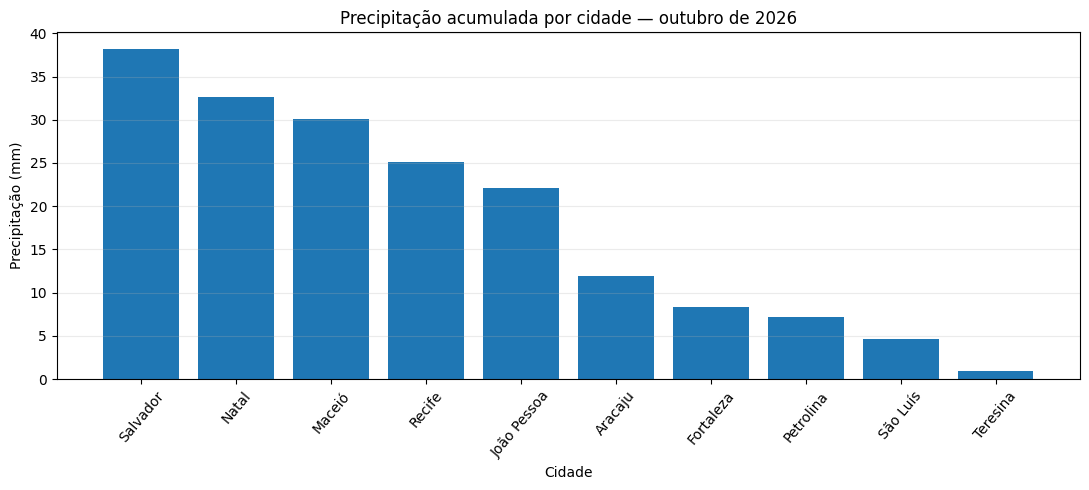

In [12]:
# Gráfico de barras: precipitação mensal por cidade.
ordem = df_final.sort_values("precip_total_mm", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(ordem["cidade"], ordem["precip_total_mm"])
ax.set_title("Precipitação acumulada por cidade — outubro de 2026")
ax.set_ylabel("Precipitação (mm)")
ax.set_xlabel("Cidade")
ax.tick_params(axis="x", rotation=50)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("grafico_precipitacao_outubro_2026.png", dpi=180, bbox_inches="tight")
plt.show()


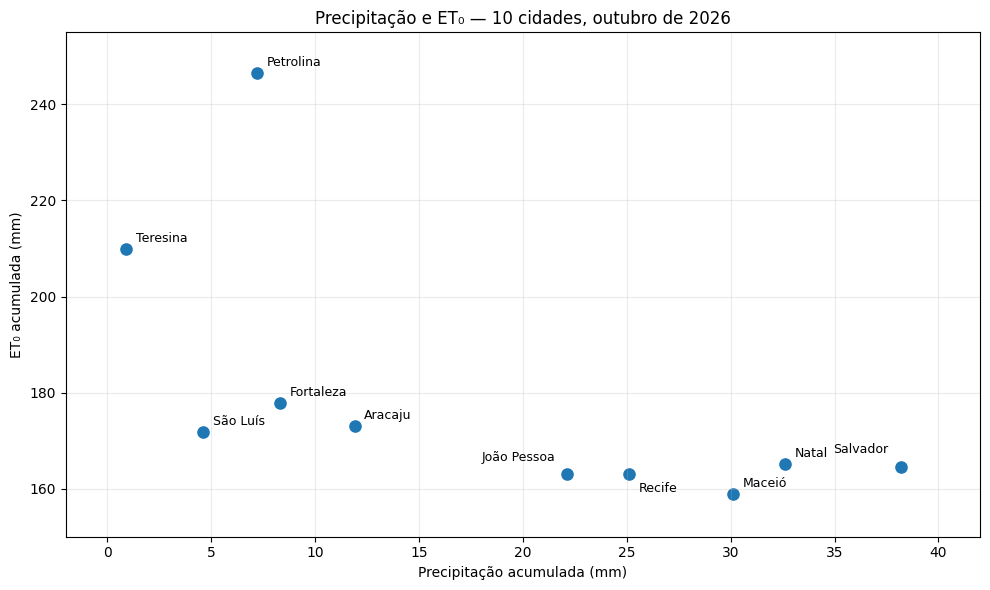

In [13]:
# Gráfico de dispersão: precipitação versus evapotranspiração de referência.
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_final["precip_total_mm"], df_final["et0_total_mm"], s=65)
# Pequenos deslocamentos evitam a sobreposição dos nomes no gráfico.
deslocamentos = {
    "João Pessoa": (-8, 9, "right"),
    "Recife": (7, -13, "left"),
    "Salvador": (-9, 10, "right"),
}
for _, linha in df_final.iterrows():
    dx, dy, ha = deslocamentos.get(linha["cidade"], (7, 5, "left"))
    ax.annotate(linha["cidade"], (linha["precip_total_mm"], linha["et0_total_mm"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=9)
ax.set_xlim(-2, 42)
ax.set_ylim(150, 255)
ax.set_title("Precipitação e ET₀ — 10 cidades, outubro de 2026")
ax.set_xlabel("Precipitação acumulada (mm)")
ax.set_ylabel("ET₀ acumulada (mm)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("grafico_precipitacao_et0_outubro_2026.png", dpi=180, bbox_inches="tight")
plt.show()


## 6. INSIGHTS
Os resultados abaixo são calculados novamente a partir do DataFrame, evitando afirmações fixas que possam divergir de uma coleta futura.

In [14]:
insights = [
    f"Entre as cidades analisadas, {mais_quente['cidade']} teve a maior temperatura média mensal ({mais_quente['temp_media_c']:.2f} °C).",
    f"{mais_chuvosa['cidade']} apresentou o maior acumulado de precipitação ({mais_chuvosa['precip_total_mm']:.2f} mm).",
    f"{maior_et0['cidade']} registrou a maior ET₀ acumulada ({maior_et0['et0_total_mm']:.2f} mm), um indicador atmosférico de demanda evaporativa em uma superfície de referência.",
]
for i, frase in enumerate(insights, 1):
    print(f"{i}. {frase}")


1. Entre as cidades analisadas, Teresina teve a maior temperatura média mensal (30.96 °C).
2. Salvador apresentou o maior acumulado de precipitação (38.20 mm).
3. Petrolina registrou a maior ET₀ acumulada (246.45 mm), um indicador atmosférico de demanda evaporativa em uma superfície de referência.


## 7. LIMITAÇÕES

- Um único mês: os dados não permitem caracterizar o clima de longo prazo nem identificar tendências climáticas.
- Reanálise meteorológica: valores estimados para células de grade, e não medições instrumentais na propriedade agrícola.
- Amostra não aleatória: dez cidades escolhidas por interesse didático; resultados não representam todo o Nordeste.
- Biologia Vegetal: as variáveis são condicionantes ambientais, mas não foram medidos crescimento, produtividade, solo ou disponibilidade real de água.
- Modo offline: se o serviço não estiver disponível, o snapshot reproduz valores consultados em 08/11/2026, sem comprovar uma nova chamada à API naquele momento.

## 8. PRÓXIMOS PASSOS
-Avaliar séries históricas de diversos anos para uma análise climática verdadeira.

-Incorporar dados de solo ou índices de vegetação e avaliar relações com características agronômicas.

-Comparar estimativas da reanálise com observações de estações meteorológicas.

## 9. CÓDIGO
O projeto foi desenvolvido em Python, utilizando o Google Colab como ambiente de programação e execução. O notebook reúne as etapas de coleta de dados por meio da API Open-Meteo, tratamento e organização com Pandas, análise exploratória, geração de gráficos e exportação do dataset final em CSV.

Código-fonte e notebook: https://colab.research.google.com/drive/1CnIoqDJaReQGkCdjOW8CINcD2ACcMM4J?usp=sharing



## 10. REFERÊNCIAS
- OPEN-METEO. Historical Weather API. https://open-meteo.com/en/docs/historical-weather-api.

- PEREIRA, Danilo. Aula 4.1: Coleta de Dados — Projeto Prático Completo e Aula 4.2: Processamento e Coleta de Dados. Material didático fornecido.

**Texto para o Audio**

Escolhi trabalhar com dados climáticos porque minha área de atuação é a Biologia Vegetal, e fatores como temperatura, precipitação e disponibilidade de água influenciam diretamente a germinação das sementes, o crescimento e o desenvolvimento das plantas. Neste projeto, utilizei a API Open-Meteo para coletar dados meteorológicos de dez cidades do Nordeste brasileiro, referentes a outubro de 2026. Foram obtidas 310 observações diárias, posteriormente organizadas em dez registros mensais. Com Python e Pandas, realizei o processamento e a análise dos dados, identificando, por exemplo, que Teresina apresentou a maior temperatura média, de 30,96 °C. Além de aprender a coletar e tratar dados reais, essa atividade mostrou como posso aplicar a Ciência de Dados na minha área de pesquisa. Futuramente, pretendo utilizar esses conhecimentos para integrar informações climáticas a dados experimentais de germinação, crescimento e desenvolvimento vegetal, investigando como as condições ambientais se relacionam com as respostas das plantas.